In [1]:
import pandas as pd

df = pd.read_csv("../dataset/spotify dataset.csv")

print(df.shape)
df.head()

(32833, 23)


,track_id,track_name,track_artist,track_popularity,track_album_id,track_album_name,track_album_release_date,playlist_name,playlist_id,playlist_genre,...,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms
0,6f807x0ima9a1j3VPbc7VN,I Don't Care (with Justin Bieber) - Loud Luxur...,Ed Sheeran,66,2oCs0DGTsRO98Gh5ZSl2Cx,I Don't Care (with Justin Bieber) [Loud Luxury...,2019-06-14,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,6,-2.634,1,0.0583,0.1020,0.000000,0.0653,0.518,122.036,194754
1,0r7CVbZTWZgbTCYdfa2P31,Memories - Dillon Francis Remix,Maroon 5,67,63rPSO264uRjW1X5E6cWv6,Memories (Dillon Francis Remix),2019-12-13,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,11,-4.969,1,0.0373,0.0724,0.004210,0.3570,0.693,99.972,162600
2,1z1Hg7Vb0AhHDiEmnDE79l,All the Time - Don Diablo Remix,Zara Larsson,70,1HoSmj2eLcsrR0vE9gThr4,All the Time (Don Diablo Remix),2019-07-05,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,1,-3.432,0,0.0742,0.0794,0.000023,0.1100,0.613,124.008,176616
3,75FpbthrwQmzHlBJLuGdC7,Call You Mine - Keanu Silva Remix,The Chainsmokers,60,1nqYsOef1yKKuGOVchbsk6,Call You Mine - The Remixes,2019-07-19,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,7,-3.778,1,0.1020,0.0287,0.000009,0.2040,0.277,121.956,169093
4,1e8PAfcKUYoKkxPhrHqw4x,Someone You Loved - Future Humans Remix,Lewis Capaldi,69,7m7vv9wlQ4i0LFuJiE2zsQ,Someone You Loved (Future Humans Remix),2019-03-05,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,1,-4.672,1,0.0359,0.0803,0.000000,0.0833,0.725,123.976,189052


In [2]:
df.columns


Index(['track_id', 'track_name', 'track_artist', 'track_popularity',
       'track_album_id', 'track_album_name', 'track_album_release_date',
       'playlist_name', 'playlist_id', 'playlist_genre', 'playlist_subgenre',
       'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness',
       'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo',
       'duration_ms'],
      dtype='str')

In [3]:
df.isnull().sum()

track_id                    0
track_name                  5
track_artist                5
track_popularity            0
track_album_id              0
track_album_name            5
track_album_release_date    0
playlist_name               0
playlist_id                 0
playlist_genre              0
playlist_subgenre           0
danceability                0
energy                      0
key                         0
loudness                    0
mode                        0
speechiness                 0
acousticness                0
instrumentalness            0
liveness                    0
valence                     0
tempo                       0
duration_ms                 0
dtype: int64

In [4]:
df.duplicated().sum()

np.int64(0)

In [5]:
df = df.drop_duplicates()


In [6]:
df["track_album_release_date"] = pd.to_datetime(
    df["track_album_release_date"],
    errors="coerce"
)

In [7]:
df["duration_min"] = df["duration_ms"] / 60000

In [8]:
df["release_year"] = df["track_album_release_date"].dt.year

Matplotlib is building the font cache; this may take a moment.


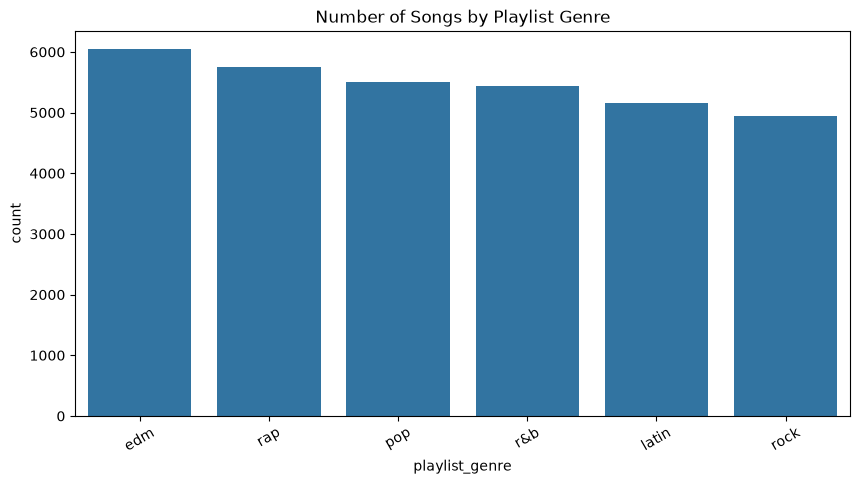

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10,5))

sns.countplot(
    data=df,
    x="playlist_genre",
    order=df["playlist_genre"].value_counts().index
)

plt.title("Number of Songs by Playlist Genre")
plt.xticks(rotation=30)
plt.show()

C:\Users\joshpin freshlin\Desktop\Spotify-Genre-Segmentation\venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 128293 (\N{FIRE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


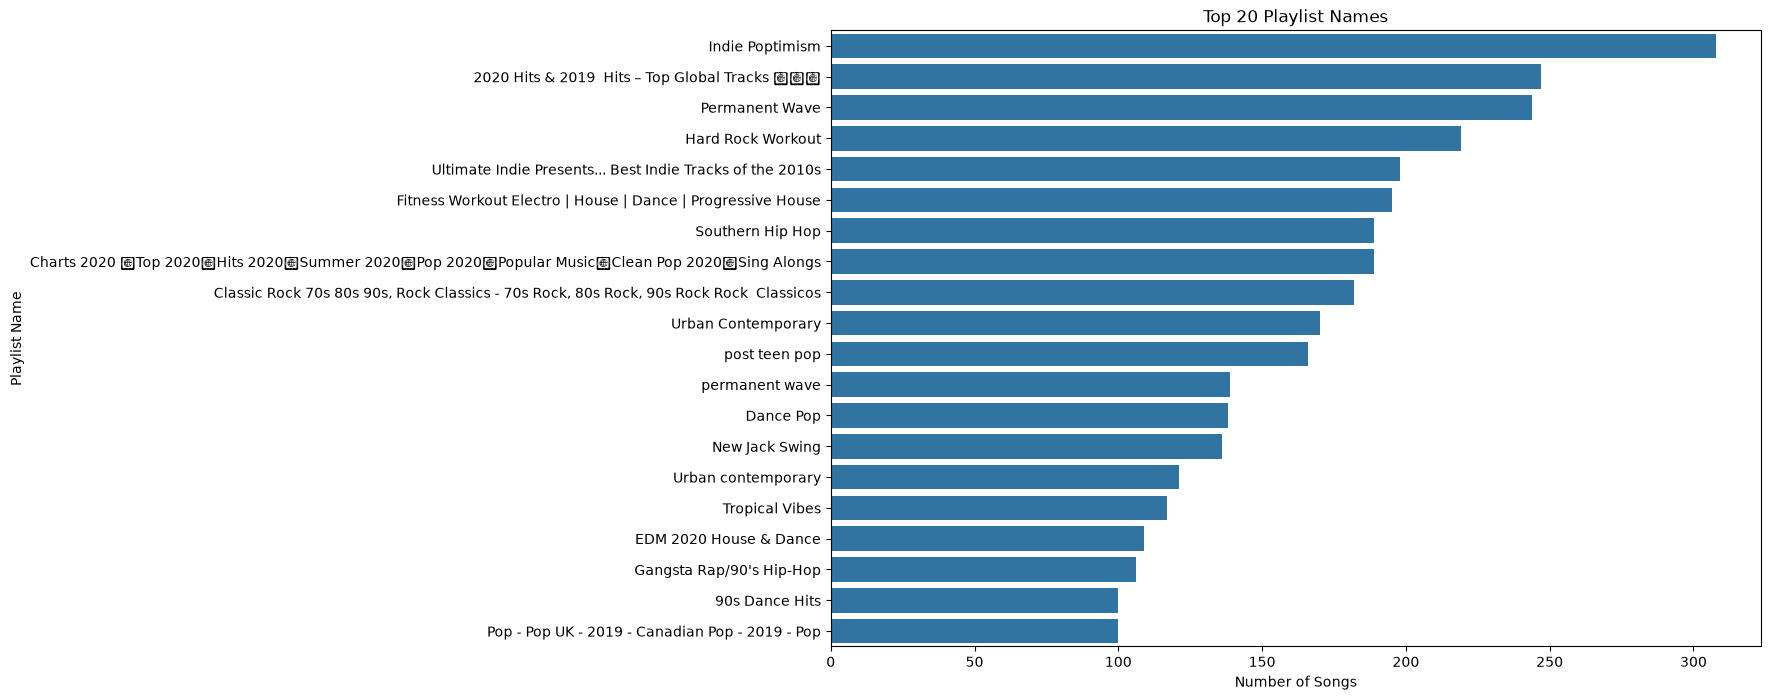

In [10]:
top_playlists = df["playlist_name"].value_counts().head(20)

plt.figure(figsize=(12,8))

sns.barplot(
    x=top_playlists.values,
    y=top_playlists.index
)

plt.title("Top 20 Playlist Names")
plt.xlabel("Number of Songs")
plt.ylabel("Playlist Name")

plt.show()

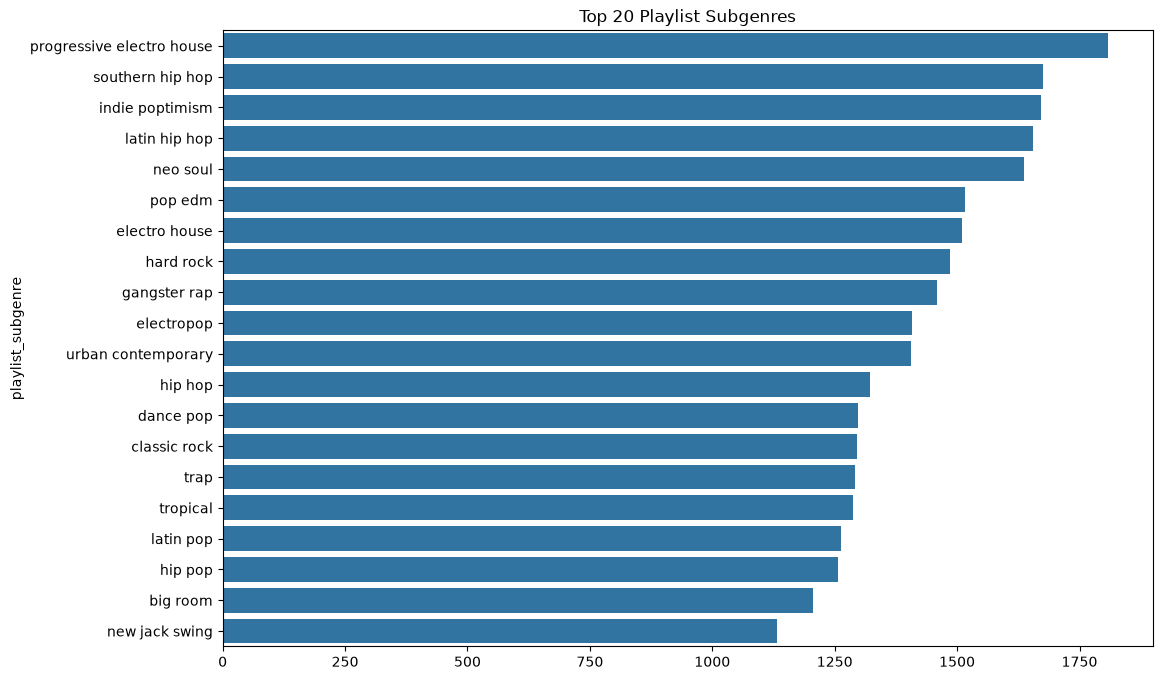

In [11]:
top_subgenres = df["playlist_subgenre"].value_counts().head(20)

plt.figure(figsize=(12,8))

sns.barplot(
    x=top_subgenres.values,
    y=top_subgenres.index
)

plt.title("Top 20 Playlist Subgenres")
plt.show()

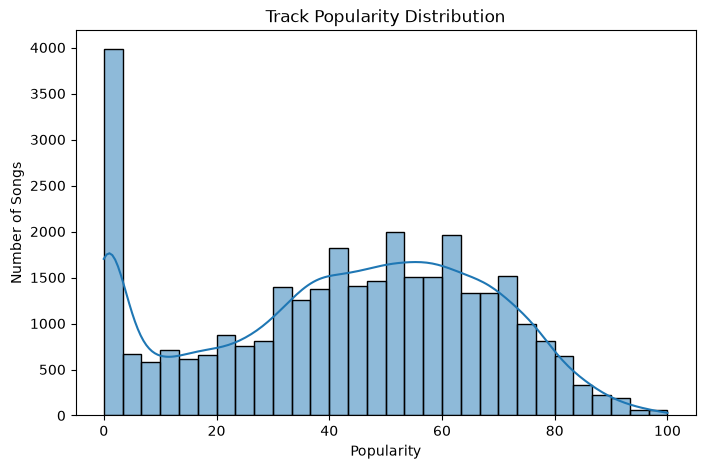

In [12]:
plt.figure(figsize=(8,5))

sns.histplot(
    df["track_popularity"],
    bins=30,
    kde=True
)

plt.title("Track Popularity Distribution")
plt.xlabel("Popularity")
plt.ylabel("Number of Songs")

plt.show()

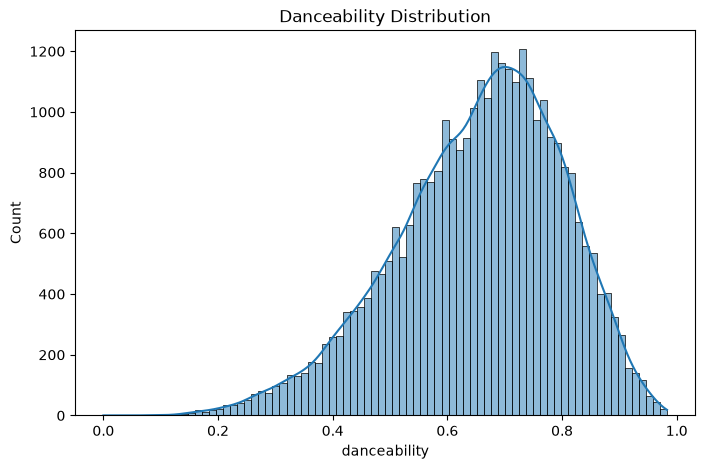

In [13]:
plt.figure(figsize=(8,5))

sns.histplot(df["danceability"], kde=True)

plt.title("Danceability Distribution")
plt.show()

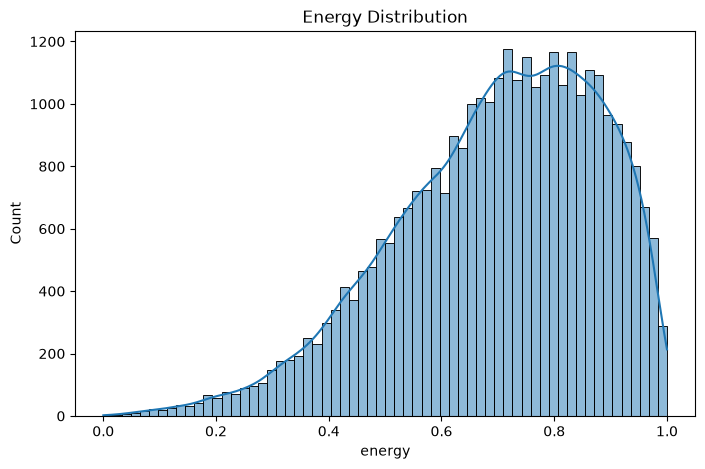

In [14]:
plt.figure(figsize=(8,5))

sns.histplot(df["energy"], kde=True)

plt.title("Energy Distribution")
plt.show()

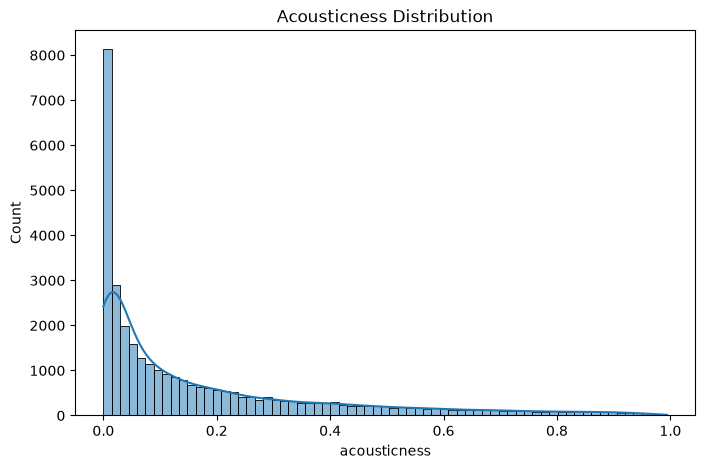

In [15]:
plt.figure(figsize=(8,5))

sns.histplot(df["acousticness"], kde=True)

plt.title("Acousticness Distribution")
plt.show()

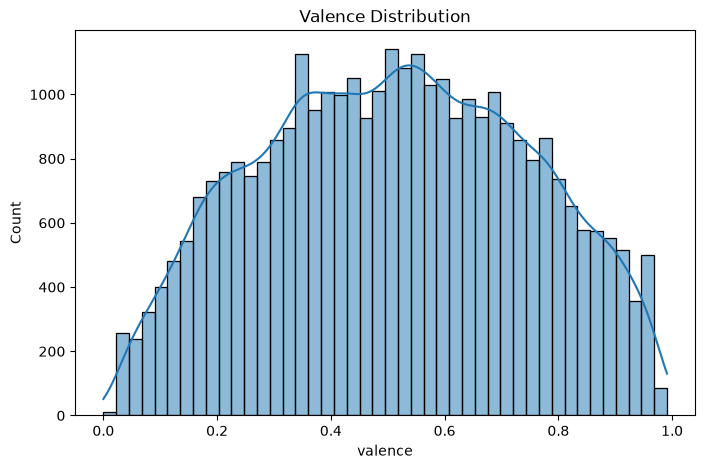

In [16]:
plt.figure(figsize=(8,5))

sns.histplot(df["valence"], kde=True)

plt.title("Valence Distribution")
plt.show()

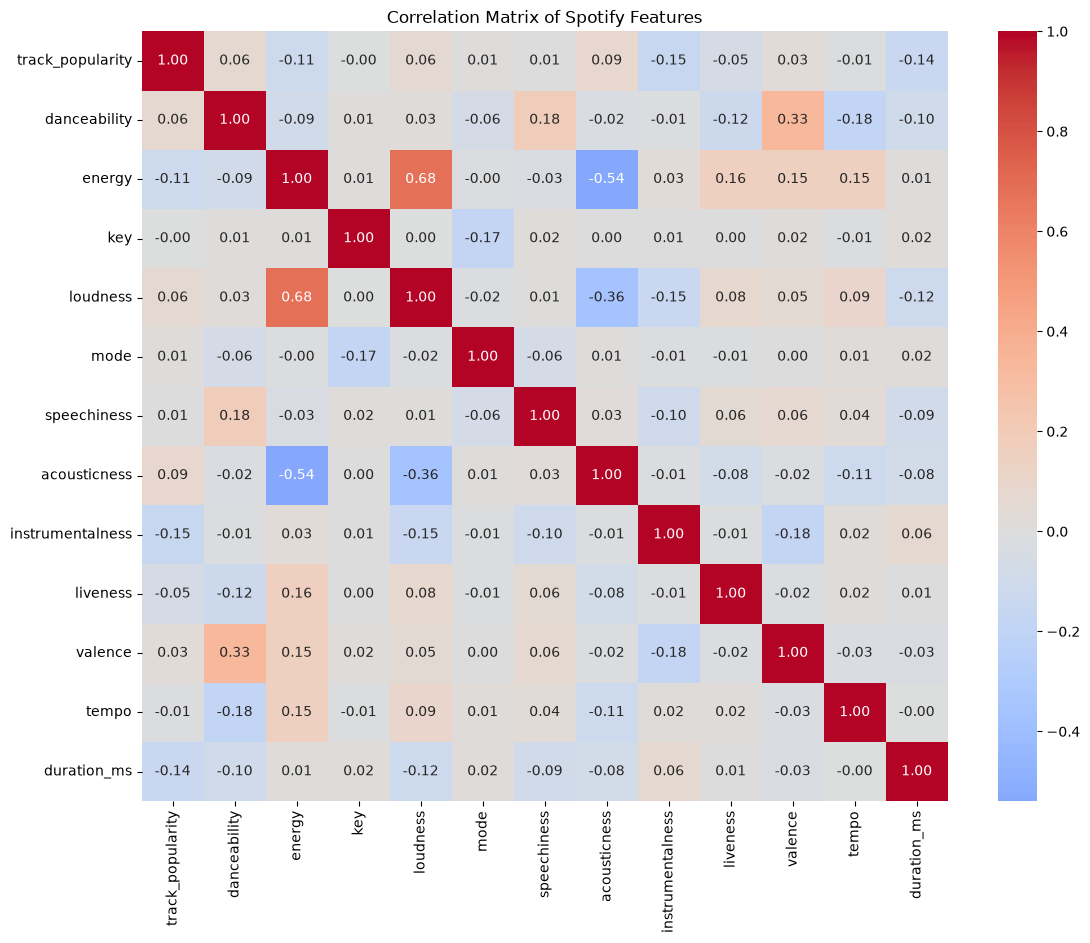

In [17]:
numeric_columns = [
    "track_popularity",
    "danceability",
    "energy",
    "key",
    "loudness",
    "mode",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence",
    "tempo",
    "duration_ms"
]

correlation = df[numeric_columns].corr()

plt.figure(figsize=(13,10))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix of Spotify Features")
plt.show()

In [18]:
audio_features = [
    "danceability",
    "energy",
    "loudness",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence",
    "tempo"
]

genre_analysis = df.groupby(
    "playlist_genre"
)[audio_features].mean()

genre_analysis

,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
playlist_genre,,,,,,,,,
edm,0.655041,0.802476,-5.427445,0.086695,0.081504,0.218578,0.211859,0.400656,125.768024
latin,0.713287,0.708312,-6.264455,0.102653,0.210920,0.044447,0.180626,0.605510,118.622354
pop,0.639302,0.701028,-6.315328,0.073991,0.170794,0.059876,0.176833,0.503521,120.743178
r&b,0.670179,0.590934,-7.864848,0.116792,0.259904,0.028920,0.175268,0.531231,114.222156
rap,0.718353,0.650708,-7.042269,0.197506,0.192479,0.075997,0.191654,0.505090,120.654908
rock,0.520548,0.732813,-7.588895,0.057696,0.145189,0.062417,0.203135,0.537352,124.988786


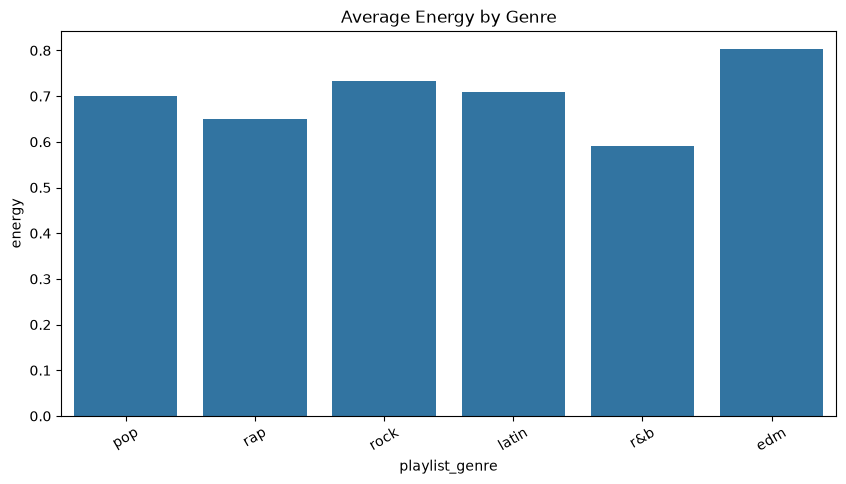

In [19]:
plt.figure(figsize=(10,5))

sns.barplot(
    data=df,
    x="playlist_genre",
    y="energy",
    errorbar=None
)

plt.title("Average Energy by Genre")
plt.xticks(rotation=30)
plt.show()

In [20]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans

In [21]:
playlist_text = (
    df["playlist_name"]
    .fillna("unknown")
    .astype(str)
    .str.lower()
)

vectorizer = TfidfVectorizer(
    stop_words="english",
    max_features=500
)

X_text = vectorizer.fit_transform(playlist_text)

In [22]:
playlist_kmeans = KMeans(
    n_clusters=8,
    random_state=42,
    n_init=10
)

df["playlist_name_cluster"] = playlist_kmeans.fit_predict(X_text)

In [23]:
df["playlist_name_cluster"].value_counts()

playlist_name_cluster
2    15728
5     3959
7     3433
4     3302
3     2701
0     1640
1     1216
6      854
Name: count, dtype: int64

In [24]:
cluster_features = [
    "danceability",
    "energy",
    "loudness",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence",
    "tempo"
]

In [25]:
from sklearn.preprocessing import StandardScaler

X = df[cluster_features].copy()

X = X.fillna(X.median())

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [26]:
from sklearn.cluster import KMeans

inertias = []

for k in range(2, 11):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X_scaled)

    inertias.append(model.inertia_)

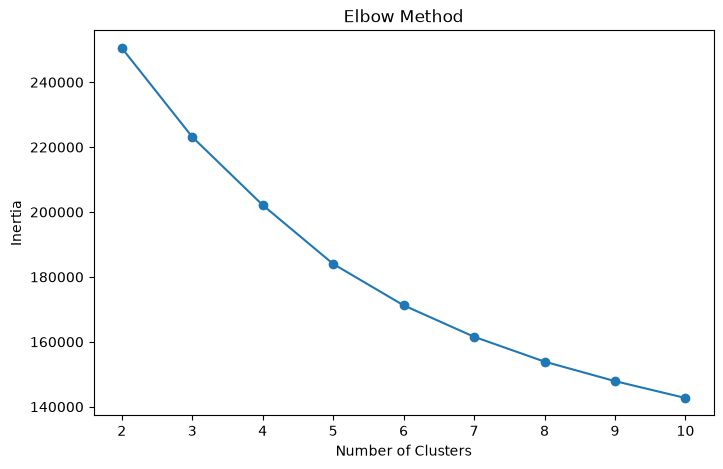

In [27]:
plt.figure(figsize=(8,5))

plt.plot(
    range(2,11),
    inertias,
    marker="o"
)

plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.title("Elbow Method")

plt.show()

In [28]:
N_CLUSTERS = 6

In [29]:
kmeans = KMeans(
    n_clusters=6,
    random_state=42,
    n_init=10
)

df["audio_cluster"] = kmeans.fit_predict(X_scaled)

In [30]:
df["audio_cluster"].value_counts()

audio_cluster
4    10663
2     8592
1     4633
0     4325
5     2464
3     2156
Name: count, dtype: int64

In [31]:
from sklearn.metrics import silhouette_score

score = silhouette_score(
    X_scaled,
    df["audio_cluster"]
)

print("Silhouette Score:", score)

Silhouette Score: 0.1585195647149825


In [32]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

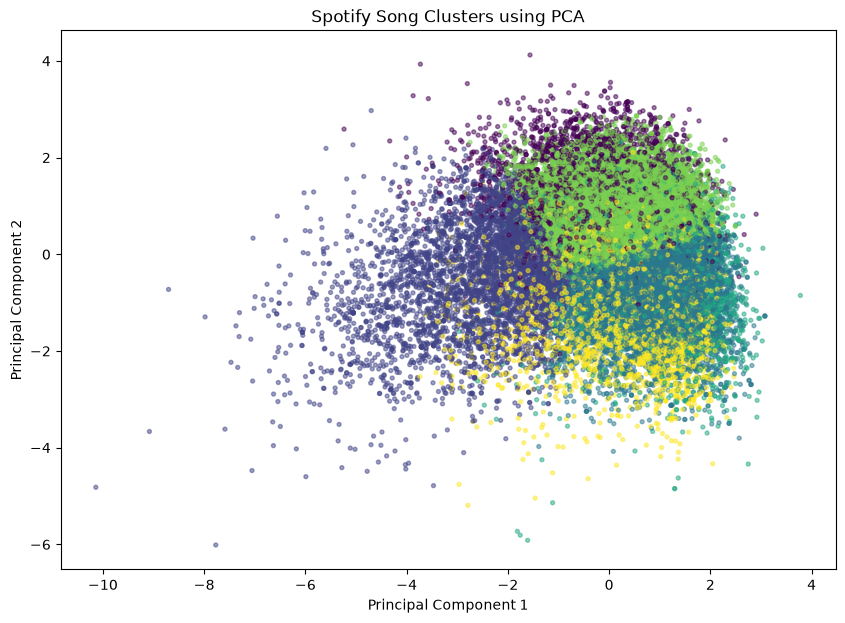

In [33]:
plt.figure(figsize=(10,7))

plt.scatter(
    X_pca[:,0],
    X_pca[:,1],
    c=df["audio_cluster"],
    s=8,
    alpha=0.5
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.title("Spotify Song Clusters using PCA")

plt.show()

In [34]:
cluster_profile = df.groupby(
    "audio_cluster"
)[cluster_features + ["track_popularity"]].mean()

cluster_profile

,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,track_popularity
audio_cluster,,,,,,,,,,
0,0.725253,0.662980,-6.831163,0.313285,0.184111,0.010299,0.175052,0.543610,122.720167,43.902428
1,0.604316,0.424556,-10.503721,0.072700,0.521537,0.089981,0.148213,0.390999,112.276265,44.346428
2,0.548642,0.791683,-5.304109,0.071181,0.068429,0.022788,0.172345,0.381028,132.434144,41.588105
3,0.609220,0.780238,-5.974000,0.109985,0.113393,0.053912,0.610803,0.509684,121.882779,38.898423
4,0.741284,0.721892,-6.260341,0.075067,0.142856,0.014864,0.148135,0.682454,113.407854,45.336397
5,0.662511,0.779845,-6.982927,0.070793,0.076495,0.751036,0.171691,0.385941,125.011423,30.317776


In [35]:
cluster_genre = pd.crosstab(
    df["audio_cluster"],
    df["playlist_genre"],
    normalize="index"
)

cluster_genre

playlist_genre,edm,latin,pop,r&b,rap,rock
audio_cluster,,,,,,
0,0.064277,0.135260,0.058497,0.199769,0.532254,0.009942
1,0.044895,0.116771,0.170300,0.331966,0.144615,0.191453
2,0.278282,0.086825,0.212058,0.076234,0.089153,0.257449
3,0.260668,0.140538,0.135436,0.127551,0.151206,0.184601
4,0.110663,0.261652,0.194317,0.187658,0.134484,0.111226
5,0.577922,0.077110,0.113231,0.039773,0.100649,0.091315


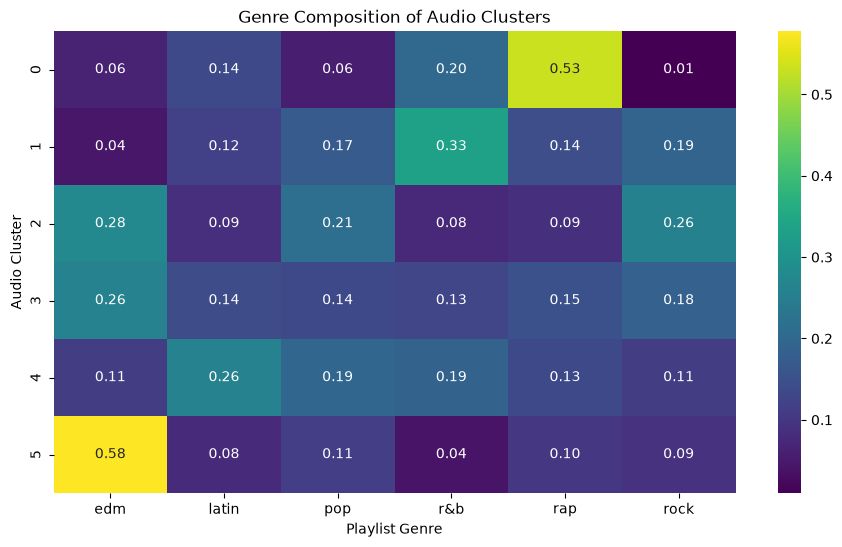

In [36]:
plt.figure(figsize=(11,6))

sns.heatmap(
    cluster_genre,
    annot=True,
    fmt=".2f",
    cmap="viridis"
)

plt.title("Genre Composition of Audio Clusters")

plt.xlabel("Playlist Genre")
plt.ylabel("Audio Cluster")

plt.show()

In [37]:
from sklearn.metrics.pairwise import cosine_similarity

similarity_matrix = cosine_similarity(X_scaled)

In [40]:
import os
import joblib

# Create outputs folder if it doesn't exist
os.makedirs("../outputs", exist_ok=True)

# Save KMeans model
joblib.dump(kmeans, "../outputs/kmeans_model.joblib")

# Save scaler
joblib.dump(scaler, "../outputs/scaler.joblib")

print("Models saved successfully!")

Models saved successfully!


In [41]:
os.makedirs("../outputs", exist_ok=True)

In [ ]:
df.to_csv(
    "../outputs/processed_spotify_data.csv",
    index=False
)